# CodeGuard AI · Experiment 03: Train and evaluate models on Devign (C)

**Goal:** teach a model to guess whether a C function is **safe (0)** or **vulnerable (1)**, and measure honestly how well it does.

**Steps**
1. Load the clean data from Experiment 02
2. Split into training and test sets, keeping each commit on one side
3. Turn code into numbers (TF-IDF)
4. Compare six models using only the training data (cross-validation)
5. Test the best model once on the test set: scores, confusion matrix, ROC and PR curves, calibration
6. See which words the model relies on
7. Why our first (leaky) experiment looked better than it was
8. Save the results

> Reminder: this is **C** code. The scanner's model is trained on Python in Experiment 05. This notebook shows the method and gives an honest first benchmark.

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, train_test_split, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibrationDisplay
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

warnings.filterwarnings("ignore")
SEED = 42
ARTIFACTS = Path("../artifacts")
(ARTIFACTS / "model").mkdir(parents=True, exist_ok=True)
(ARTIFACTS / "metrics").mkdir(parents=True, exist_ok=True)
(ARTIFACTS / "figures").mkdir(parents=True, exist_ok=True)

## Step 1: Load the clean data

In [2]:
df = pd.read_csv("../datasets/processed/devign_cleaned.csv")

X = df["func"]          # input: the code
y = df["target"]        # answer: 0 = safe, 1 = vulnerable
groups = df["commit_id"]

print("Functions:", len(df))
print(y.value_counts().rename({0: "Safe", 1: "Vulnerable"}))

Functions: 27138
target
Safe          14772
Vulnerable    12366
Name: count, dtype: int64


## Step 2: Split into training and test sets

- **Training set (80%)**: the model learns from this.
- **Test set (20%)**: kept hidden until the very end, like a final exam.

We split **by commit**: all functions from one commit go to the same side. Functions from the same commit share a label and often look alike, so splitting them would let the model "peek" at the test set.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Training: {len(X_train)} functions ({y_train.mean():.0%} vulnerable)")
print(f"Test:     {len(X_test)} functions ({y_test.mean():.0%} vulnerable)")
print("Commits in both sets:", len(set(groups_train) & set(groups.iloc[test_idx])))

Training: 21901 functions (46% vulnerable)
Test:     5237 functions (45% vulnerable)
Commits in both sets: 0


## Step 3: Turn code into numbers with TF-IDF

Models only understand numbers. **TF-IDF** turns each function into a list of numbers, one per word:

- **TF (term frequency):** how often a word appears in this function.
- **IDF (inverse document frequency):** words that appear in *every* function (like `return`) get a low weight; rarer words get a higher weight.

We also count pairs of neighbouring words (like `if buf`), called **bigrams**.

**Limit:** TF-IDF only counts words. It does not understand order, logic or data flow, so it cannot really "see" a missing bounds check.

TF-IDF and the model are joined in a **pipeline**, so TF-IDF learns its vocabulary from training data only. This avoids another kind of leakage.

In [4]:
def make_tfidf():
    return TfidfVectorizer(
        token_pattern=r"\b\w+\b",  # a "word" = letters, digits or _
        ngram_range=(1, 2),          # single words and word pairs
        max_features=5000,           # keep the 5,000 most common
        sublinear_tf=True,           # soften very repeated words
    )

## Step 4: Compare six models (training data only)

| Model | Idea in one line |
|---|---|
| **Baseline** | Always guesses the most common answer (*safe*). Any real model must beat it. |
| **Logistic Regression** | Gives each word a weight, adds them up, turns the total into a probability. Simple and explainable. |
| **Naive Bayes** | Counts how often each word appears in each class. Very fast, classic text baseline. |
| **Linear SVM** | Finds the line that best separates the two classes with the widest margin. Strong on sparse text features. |
| **Random Forest** | Many decision trees vote. Can capture combinations of words. |
| **XGBoost** | Trees built one after another, each fixing the previous one's mistakes. |

We use **5-fold grouped cross-validation** on the training set: split it into 5 parts (keeping commits together), train on 4, score on 1, repeat 5 times. The test set stays untouched.

`class_weight="balanced"` (or `scale_pos_weight` for XGBoost) tells models to care equally about both classes.

In [5]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Baseline (always 'safe')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Linear SVM": LinearSVC(C=0.5, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                            min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist",
                             scale_pos_weight=pos_weight, eval_metric="logloss",
                             random_state=SEED, n_jobs=-1),
}

scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = []
for name, model in models.items():
    start = time.time()
    scores = cross_validate(make_pipeline(make_tfidf(), model), X_train, y_train,
                            groups=groups_train, cv=GroupKFold(n_splits=5), scoring=scoring)
    row = {"Model": name}
    row.update({metric: scores[f"test_{metric}"].mean() for metric in scoring})
    row["F1 std"] = scores["test_f1"].std()
    row["Seconds"] = time.time() - start
    rows.append(row)
    print(f"{name:26} done in {row['Seconds']:.0f}s")

comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

Baseline (always 'safe')   done in 65s


Logistic Regression        done in 60s


Naive Bayes                done in 60s


Linear SVM                 done in 61s


Random Forest              done in 79s


XGBoost                    done in 171s


,accuracy,precision,recall,f1,roc_auc,pr_auc,F1 std,Seconds
Model,,,,,,,,
Baseline (always 'safe'),0.543,0.000,0.000,0.000,0.500,0.457,0.000,64.953
Logistic Regression,0.512,0.470,0.540,0.502,0.518,0.470,0.021,59.760
Naive Bayes,0.537,0.493,0.440,0.464,0.536,0.489,0.008,60.236
Linear SVM,0.503,0.462,0.529,0.493,0.508,0.463,0.019,60.567
Random Forest,0.489,0.441,0.431,0.435,0.470,0.434,0.012,79.411
XGBoost,0.501,0.460,0.514,0.484,0.498,0.456,0.012,170.944


### What the scores mean

- **Accuracy:** out of all functions, how many did we label correctly?
- **Precision:** out of the functions we called *vulnerable*, how many really were? (High = few false alarms.)
- **Recall:** out of all truly vulnerable functions, how many did we catch? (High = few missed bugs.)
- **F1:** one number that balances precision and recall. We pick the model with the best F1.
- **ROC-AUC:** if we pick one vulnerable and one safe function at random, how often does the model give the vulnerable one a higher score? 0.5 = coin flip, 1.0 = perfect.
- **PR-AUC:** average precision across all thresholds. The coin-flip level equals the share of vulnerable functions (about 0.46 here).

The baseline has F1 = 0 because it never predicts *vulnerable*.

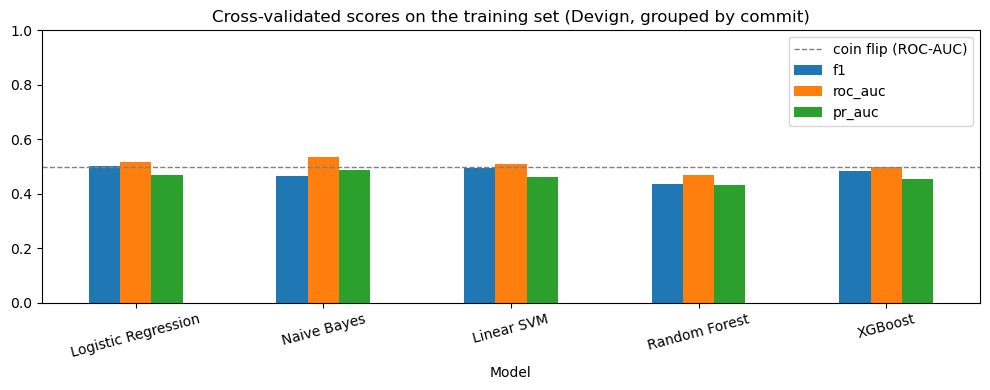

Best model by cross-validated F1: Logistic Regression


In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
comparison.drop(index="Baseline (always 'safe')")[["f1", "roc_auc", "pr_auc"]].plot.bar(ax=ax, rot=15)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1, label="coin flip (ROC-AUC)")
ax.set_ylim(0, 1)
ax.set_title("Cross-validated scores on the training set (Devign, grouped by commit)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(ARTIFACTS / "figures" / "devign_cv_comparison.png", dpi=120)
plt.show()

best_name = comparison["f1"].idxmax()
print("Best model by cross-validated F1:", best_name)

## Step 5: Final exam on the test set

We retrain the best model on all the training data, then test it **once** on the hidden test set.

In [7]:
final_model = make_pipeline(make_tfidf(), models[best_name])
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

if hasattr(final_model, "predict_proba"):
    y_score = final_model.predict_proba(X_test)[:, 1]
else:
    y_score = final_model.decision_function(X_test)

test_results = {
    "model": best_name,
    "test_size": int(len(y_test)),
    "accuracy": round(accuracy_score(y_test, y_pred), 3),
    "precision": round(precision_score(y_test, y_pred), 3),
    "recall": round(recall_score(y_test, y_pred), 3),
    "f1": round(f1_score(y_test, y_pred), 3),
    "roc_auc": round(roc_auc_score(y_test, y_score), 3),
    "pr_auc": round(average_precision_score(y_test, y_score), 3),
    "baseline_accuracy": round((y_test == 0).mean(), 3),
    "baseline_pr_auc": round(y_test.mean(), 3),
}
for k, v in test_results.items():
    print(f"{k:18} {v}")

model              Logistic Regression
test_size          5237
accuracy           0.545
precision          0.496
recall             0.567
f1                 0.529
roc_auc            0.561
pr_auc             0.498
baseline_accuracy  0.549
baseline_pr_auc    0.451


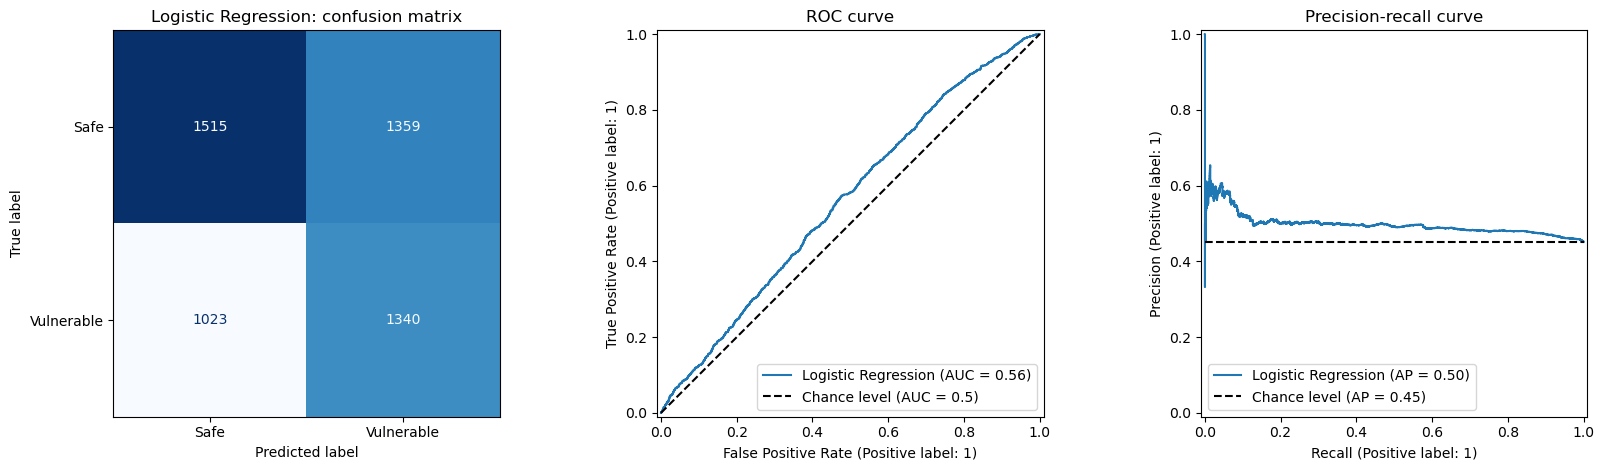

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Safe", "Vulnerable"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"{best_name}: confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[1], name=best_name, plot_chance_level=True)
axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, y_score, ax=axes[2], name=best_name, plot_chance_level=True)
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.savefig(ARTIFACTS / "figures" / "devign_test_curves.png", dpi=120)
plt.show()

### How to read these charts

|  | Predicted safe | Predicted vulnerable |
|---|---|---|
| **Actually safe** | Correct ✔ | **False alarm** (wastes developer time) |
| **Actually vulnerable** | **Missed bug** (security risk) | Correct ✔ |

- **ROC curve:** the closer it hugs the top-left corner, the better. The dashed diagonal is a coin flip.
- **PR curve:** the higher, the better. The dashed line is the share of vulnerable functions — what a coin flip gets.

In security, missed bugs are usually worse than false alarms, so we watch **recall** closely.

### Can we trust the score as a confidence?

A **calibration plot** checks whether a score of 0.7 means "vulnerable about 7 times in 10". Points on the diagonal = well calibrated.

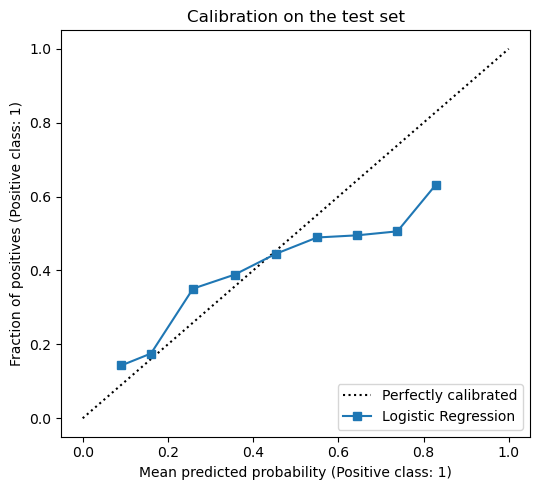

In [9]:
if hasattr(final_model, "predict_proba"):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    CalibrationDisplay.from_predictions(y_test, y_score, n_bins=10, ax=ax, name=best_name)
    ax.set_title("Calibration on the test set")
    plt.tight_layout()
    plt.show()
else:
    print(best_name, "gives margins, not probabilities, so a calibration plot does not apply.")

## Step 6: Which words does the model rely on?

For linear models, each word has a weight. Positive weight = pushes towards *vulnerable*; negative = towards *safe*.

In [10]:
tfidf = final_model[0]
model = final_model[-1]
names = tfidf.get_feature_names_out()

if hasattr(model, "coef_"):
    weights = pd.Series(np.ravel(model.coef_), index=names)
    print("Top 10 words pointing to VULNERABLE:")
    print(weights.nlargest(10).round(2).to_string())
    print()
    print("Top 10 words pointing to SAFE:")
    print(weights.nsmallest(10).round(2).to_string())
elif hasattr(model, "feature_log_prob_"):
    weights = pd.Series(model.feature_log_prob_[1] - model.feature_log_prob_[0], index=names)
    print("Top 10 words pointing to VULNERABLE (log-probability difference):")
    print(weights.nlargest(10).round(2).to_string())
else:
    weights = pd.Series(model.feature_importances_, index=names)
    print("Top 15 most important words:")
    print(weights.nlargest(15).round(4).to_string())

Top 10 words pointing to VULNERABLE:
opaque hwaddr    2.04
dead_tmp         1.98
rdma             1.95
ogg              1.88
tb cflags        1.79
cpu cpu          1.75
temp             1.72
t2               1.71
2 1              1.69
cpustate cpu     1.69

Top 10 words pointing to SAFE:
opaque target_phys_addr_t   -3.27
fail_unless                 -2.91
target_phys_addr_t          -2.45
pix                         -2.44
coded_frame                 -2.01
fp_status                   -1.99
cpu_tmp0                    -1.82
dst const                   -1.82
__function__                -1.79
iommu                       -1.76


**Be careful interpreting this.** Many top words are names from QEMU or FFmpeg, not real security signals. The model is partly learning *which part of which project* tends to have bugs, not *what makes code unsafe*.

## Step 7: Why our first experiment looked better than it was

Our very first notebook (now in `archive/00_leaky_split_v0.ipynb`) used a **random** split: functions from the same commit could land in both training and test sets. Here we run Logistic Regression with both split methods on the same data, so the effect is visible.

In [11]:
def split_score(train_i, test_i):
    pipe = make_pipeline(make_tfidf(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    pipe.fit(X.iloc[train_i], y.iloc[train_i])
    pred = pipe.predict(X.iloc[test_i])
    return {"accuracy": accuracy_score(y.iloc[test_i], pred), "f1": f1_score(y.iloc[test_i], pred),
            "shared commits": len(set(groups.iloc[train_i]) & set(groups.iloc[test_i]))}

all_idx = np.arange(len(df))
rand_train, rand_test = train_test_split(all_idx, test_size=0.2, random_state=SEED, stratify=y)

leak_table = pd.DataFrame({
    "Random split (leaky)": split_score(rand_train, rand_test),
    "Split by commit (honest)": split_score(train_idx, test_idx),
}).T.round(3)
leak_table

,accuracy,f1,shared commits
Random split (leaky),0.598,0.581,1873.0
Split by commit (honest),0.545,0.529,0.0


**What this shows:** with a random split, thousands of commits appear on both sides, so the model can recognise them. Compare the two rows: any gap is "free" performance that would not exist on new code. We always use the honest split.

## Step 8: Save the results

The C model is saved for reference only; the scanner never uses it on Python code.

In [12]:
joblib.dump(final_model, ARTIFACTS / "model" / "devign_c_model.joblib")
with open(ARTIFACTS / "metrics" / "devign_results.json", "w") as f:
    json.dump({"dataset": "Devign (C), full, cleaned",
               "split": "GroupShuffleSplit by commit_id, 80/20, seed 42",
               "cross_validation": comparison.reset_index().to_dict(orient="records"),
               "test": test_results,
               "leakage_check": leak_table.reset_index(names="split").to_dict(orient="records")},
              f, indent=2)
print("Saved artifacts/model/devign_c_model.joblib and artifacts/metrics/devign_results.json")

Saved artifacts/model/devign_c_model.joblib and artifacts/metrics/devign_results.json


## Conclusion

| | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Baseline (always safe), test | 0.549 | — | 0 | 0 | 0.5 | 0.451 |
| **Logistic Regression, test (5,237 functions)** | **0.545** | **0.496** | **0.567** | **0.529** | **0.561** | **0.498** |

1. **Result:** Logistic Regression had the best cross-validated F1 (0.502) and scored F1 = 0.529 on the test set. Its accuracy (0.545) is **no better than always saying "safe" (0.549)**, and ROC-AUC 0.56 is only slightly above a coin flip. All six models scored ROC-AUC between 0.47 and 0.54 in cross-validation. In simple words: word counts barely separate vulnerable from safe C functions in Devign.
2. **Leakage matters:** with a random split, 1,873 commits sat on both sides, and the same model looked better (accuracy 0.598, F1 0.581) — about **5 points of "free" performance** that would vanish on new code. This is why our first notebook's numbers were too optimistic.
3. **This is normal for Devign.** Its labels are noisy, and published models (including fine-tuned CodeBERT) reach only about 62–65% accuracy.
4. **Our method is sound and reusable:** dedup with conflict removal, commit-grouped split, cross-validated model choice, one final test, curves and calibration. Experiments 04–05 apply the same method to Python, which is what the scanner needs.

**Limits:** C only; TF-IDF ignores code order and data flow; one random split (seed 42); scores are not calibrated confidences.